# Practical 6: Descriptive Statistical Analysis
**Research topic:** Survey on ETL Pipeline Failures and AI-Assisted Troubleshooting

## 1. Import libraries and load the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

file_path = Path("survey_responses.xlsx")  
df = pd.read_excel(file_path)

print("Dataset dimensions:", df.shape)
print("Number of responses:", len(df))
display(df.head())


Dataset dimensions: (50, 11)
Number of responses: 50


,Timestamp,Q1. What best describes your current role?,Q2. How familiar are you with data pipelines and ETL processes?,"Q3. Have you ever encountered errors or failures while working with data processing workflows, databases or ETL pipelines?",Q4. Which types of data pipeline failures have you encountered or are familiar with?\n\nSelect all that apply,Q5. How frequently do you encounter data processing or pipeline failures?,Q6. How do you typically identify or investigate data processing failures?,Q7. Approximately how much time do you usually spend identifying and troubleshooting a data processing failure?,Q8. How useful do you think an automated system that detects ETL pipeline failures and identifies abnormal execution behaviour would be?,Q9. Would you trust AI-generated explanations and troubleshooting recommendations if they were reviewed and approved by a human before implementation?,Q10. What concerns would you have about using AI for automated pipeline failure detection and troubleshooting?
0,2026-11-23 08:50:39.929,Postgraduate Student,2 — Slightly familiar,Yes,"Missing or inaccessible input files, Incorrect...",Frequently,Manually inspecting error logs,15–30 minutes,4 — Very useful,4 — Agree,Inaccurate or unsafe fix recommendations
1,2026-11-23 08:51:24.794,Data Engineer,5 — Extremely familiar,Yes,"Missing or inaccessible input files, Incorrect...",Frequently,Using monitoring or logging tools,15–30 minutes,4 — Very useful,4 — Agree,High computational or API costs
2,2026-11-23 08:54:56.817,Postgraduate Student,2 — Slightly familiar,Not sure,Data transformation or processing errors,Rarely,Seeking help from colleagues or online resources,More than 1 hour,3 — Moderately useful,3 — Neutral,Other
3,2026-11-23 08:56:26.354,Other,1 — Not familiar,Not sure,I have not encountered any of these,Not applicable,Seeking help from colleagues or online resources,Not applicable / No experience,3 — Moderately useful,3 — Neutral,Data privacy and security concerns
4,2026-11-23 08:57:48.345,Software Developer,4 — Very familiar,Yes,"Invalid or missing data values, Duplicate reco...",Occasionally,Using monitoring or logging tools,15–30 minutes,5 — Extremely useful,4 — Agree,Data privacy and security concerns


## 2. Identify questionnaire columns

In [2]:

def find_question_column(prefix):
    matches = [column for column in df.columns if column.strip().startswith(prefix)]
    if not matches:
        raise ValueError(f"Could not find a column starting with {prefix}")
    return matches[0]

q1 = find_question_column("Q1.")
q2 = find_question_column("Q2.")
q3 = find_question_column("Q3.")
q4 = find_question_column("Q4.")
q5 = find_question_column("Q5.")
q6 = find_question_column("Q6.")
q7 = find_question_column("Q7.")
q8 = find_question_column("Q8.")
q9 = find_question_column("Q9.")
q10 = find_question_column("Q10.")

print("Question columns identified:", 10)


Question columns identified: 10


## 3. Data quality checks

In [3]:

quality_summary = pd.DataFrame({
    "Check": [
        "Total responses",
        "Missing cells",
        "Exact duplicate rows",
        "Responses with any missing field"
    ],
    "Count": [
        len(df),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df.isna().any(axis=1).sum())
    ]
})
display(quality_summary)

print("Missing values by column:")
display(df.isna().sum().rename("Missing values").to_frame())


,Check,Count
0,Total responses,50
1,Missing cells,0
2,Exact duplicate rows,0
3,Responses with any missing field,0


Missing values by column:


,Missing values
Timestamp,0
Q1. What best describes your current role?,0
Q2. How familiar are you with data pipelines and ETL processes?,0
"Q3. Have you ever encountered errors or failures while working with data processing workflows, databases or ETL pipelines?",0
Q4. Which types of data pipeline failures have you encountered or are familiar with?\n\nSelect all that apply,0
Q5. How frequently do you encounter data processing or pipeline failures?,0
Q6. How do you typically identify or investigate data processing failures?,0
Q7. Approximately how much time do you usually spend identifying and troubleshooting a data processing failure?,0
Q8. How useful do you think an automated system that detects ETL pipeline failures and identifies abnormal execution behaviour would be?,0
Q9. Would you trust AI-generated explanations and troubleshooting recommendations if they were reviewed and approved by a human before implementation?,0


## 4. Prepare analysis data

In [4]:

def extract_rating(series):
    # The Google Forms linear-scale answers begin with the numeric rating.
    return pd.to_numeric(
        series.astype(str).str.extract(r"^\s*(\d+)")[0],
        errors="coerce"
    )

analysis = pd.DataFrame({
    "Role": df[q1].astype(str).str.strip(),
    "ETL_Familiarity": extract_rating(df[q2]),
    "Failure_Experience": df[q3].astype(str).str.strip(),
    "Failure_Frequency": df[q5].astype(str).str.strip(),
    "Troubleshooting_Method": df[q6].astype(str).str.strip(),
    "Troubleshooting_Time": df[q7].astype(str).str.strip(),
    "Automation_Usefulness": extract_rating(df[q8]),
    "AI_Recommendation_Trust": extract_rating(df[q9])
})

display(analysis.head())

,Role,ETL_Familiarity,Failure_Experience,Failure_Frequency,Troubleshooting_Method,Troubleshooting_Time,Automation_Usefulness,AI_Recommendation_Trust
0,Postgraduate Student,2,Yes,Frequently,Manually inspecting error logs,15–30 minutes,4,4
1,Data Engineer,5,Yes,Frequently,Using monitoring or logging tools,15–30 minutes,4,4
2,Postgraduate Student,2,Not sure,Rarely,Seeking help from colleagues or online resources,More than 1 hour,3,3
3,Other,1,Not sure,Not applicable,Seeking help from colleagues or online resources,Not applicable / No experience,3,3
4,Software Developer,4,Yes,Occasionally,Using monitoring or logging tools,15–30 minutes,5,4


## 5. Frequency distributions

In [5]:

def frequency_table(series, denominator=None):
    counts = series.value_counts(dropna=False)
    if denominator is None:
        denominator = len(series)
    return pd.DataFrame({
        "Response": counts.index.astype(str),
        "Frequency": counts.values,
        "Percentage (%)": (counts.values / denominator * 100).round(2)
    })

role_frequency = frequency_table(analysis["Role"])
experience_frequency = frequency_table(analysis["Failure_Experience"])
failure_frequency = frequency_table(analysis["Failure_Frequency"])
method_frequency = frequency_table(analysis["Troubleshooting_Method"])
time_frequency = frequency_table(analysis["Troubleshooting_Time"])

print("Q1 - Respondent role")
display(role_frequency)
print("Q3 - Experience with failures")
display(experience_frequency)
print("Q5 - Failure frequency")
display(failure_frequency)
print("Q6 - Troubleshooting method")
display(method_frequency)
print("Q7 - Troubleshooting time")
display(time_frequency)


Q1 - Respondent role


,Response,Frequency,Percentage (%)
0,Data Engineer,15,30.0
1,Data Analyst,9,18.0
2,Postgraduate Student,7,14.0
3,Data Scientist,7,14.0
4,Software Developer,6,12.0
5,Undergraduate Student,5,10.0
6,Other,1,2.0


Q3 - Experience with failures


,Response,Frequency,Percentage (%)
0,Yes,41,82.0
1,Not sure,9,18.0


Q5 - Failure frequency


,Response,Frequency,Percentage (%)
0,Frequently,19,38.0
1,Occasionally,19,38.0
2,Not applicable,5,10.0
3,Rarely,4,8.0
4,Never,2,4.0
5,Very frequently,1,2.0


Q6 - Troubleshooting method


,Response,Frequency,Percentage (%)
0,Debugging the code,26,52.0
1,Manually inspecting error logs,8,16.0
2,Seeking help from colleagues or online resources,6,12.0
3,Using monitoring or logging tools,4,8.0
4,Automated alerts or notifications,3,6.0
5,I have no experience troubleshooting such fail...,3,6.0


Q7 - Troubleshooting time


,Response,Frequency,Percentage (%)
0,15–30 minutes,32,64.0
1,Not applicable / No experience,7,14.0
2,30–60 minutes,6,12.0
3,5–15 minutes,3,6.0
4,More than 1 hour,1,2.0
5,Less than 5 minutes,1,2.0


## 6. Multiple-response analysis

In [6]:
def multiple_response_table(column):
    # Google Forms exports multiple selections as comma-separated text.
    selected_options = (
        df[column].dropna().astype(str)
        .str.split(",").explode().str.strip()
    )
    counts = selected_options.value_counts()
    return pd.DataFrame({
        "Option": counts.index,
        "Selections": counts.values,
        "Respondents (%)": (counts.values / len(df) * 100).round(2)
    })

failure_types = multiple_response_table(q4)
ai_concerns = multiple_response_table(q10)

print("Q4 - Types of pipeline failures")
display(failure_types)
print("Q10 - Concerns about AI-assisted troubleshooting")
display(ai_concerns)
print("Note: Multiple selections were allowed; percentages can total more than 100%.")


Q4 - Types of pipeline failures


,Option,Selections,Respondents (%)
0,Missing or inaccessible input files,37,74.0
1,Invalid or missing data values,35,70.0
2,Incorrect or missing data columns (schema mism...,31,62.0
3,Data transformation or processing errors,11,22.0
4,Duplicate records,8,16.0
5,Configuration or permission errors,8,16.0
6,Database connection failures,7,14.0
7,I have not encountered any of these,6,12.0


Q10 - Concerns about AI-assisted troubleshooting


,Option,Selections,Respondents (%)
0,Data privacy and security concerns,26,52.0
1,Inaccurate or unsafe fix recommendations,12,24.0
2,No major concerns,4,8.0
3,Overdependence on AI systems,3,6.0
4,High computational or API costs,2,4.0
5,Other,1,2.0
6,Slow response time,1,2.0
7,Incorrect failure identification,1,2.0


Note: Multiple selections were allowed; percentages can total more than 100%.


## 7. Likert-scale frequency distributions

In [7]:

def likert_frequency(series, labels):
    counts = series.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    return pd.DataFrame({
        "Rating": [1, 2, 3, 4, 5],
        "Label": labels,
        "Frequency": counts.values,
        "Percentage (%)": (counts.values / series.notna().sum() * 100).round(2)
    })

familiarity_distribution = likert_frequency(
    analysis["ETL_Familiarity"],
    ["Not familiar", "Slightly familiar", "Moderately familiar",
     "Very familiar", "Extremely familiar"]
)
usefulness_distribution = likert_frequency(
    analysis["Automation_Usefulness"],
    ["Not useful", "Slightly useful", "Moderately useful",
     "Very useful", "Extremely useful"]
)
trust_distribution = likert_frequency(
    analysis["AI_Recommendation_Trust"],
    ["Strongly disagree", "Disagree", "Neutral", "Agree", "Strongly agree"]
)

print("Q2 - ETL familiarity")
display(familiarity_distribution)
print("Q8 - Automated detection usefulness")
display(usefulness_distribution)
print("Q9 - Trust in AI recommendations")
display(trust_distribution)


Q2 - ETL familiarity


,Rating,Label,Frequency,Percentage (%)
0,1,Not familiar,1,2.0
1,2,Slightly familiar,7,14.0
2,3,Moderately familiar,3,6.0
3,4,Very familiar,31,62.0
4,5,Extremely familiar,8,16.0


Q8 - Automated detection usefulness


,Rating,Label,Frequency,Percentage (%)
0,1,Not useful,0,0.0
1,2,Slightly useful,0,0.0
2,3,Moderately useful,7,14.0
3,4,Very useful,34,68.0
4,5,Extremely useful,9,18.0


Q9 - Trust in AI recommendations


,Rating,Label,Frequency,Percentage (%)
0,1,Strongly disagree,0,0.0
1,2,Disagree,0,0.0
2,3,Neutral,8,16.0
3,4,Agree,38,76.0
4,5,Strongly agree,4,8.0


## 8. Measures of central tendency and dispersion

In [8]:
variables = {
    "ETL familiarity": analysis["ETL_Familiarity"],
    "Automated detection usefulness": analysis["Automation_Usefulness"],
    "Trust in AI recommendations": analysis["AI_Recommendation_Trust"]
}

statistics = []
for variable_name, values in variables.items():
    values = values.dropna()
    statistics.append({
        "Variable": variable_name,
        "N": values.count(),
        "Mean": round(values.mean(), 2),
        "Median": values.median(),
        "Mode": values.mode().iloc[0],
        "Sample variance": round(values.var(ddof=1), 2),
        "Sample standard deviation": round(values.std(ddof=1), 2),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Range": values.max() - values.min()
    })

statistics_table = pd.DataFrame(statistics)
display(statistics_table)

,Variable,N,Mean,Median,Mode,Sample variance,Sample standard deviation,Minimum,Maximum,Range
0,ETL familiarity,50,3.76,4.0,4,0.92,0.96,1,5,4
1,Automated detection usefulness,50,4.04,4.0,4,0.32,0.57,3,5,2
2,Trust in AI recommendations,50,3.92,4.0,4,0.24,0.49,3,5,2


## 9. Visualizations

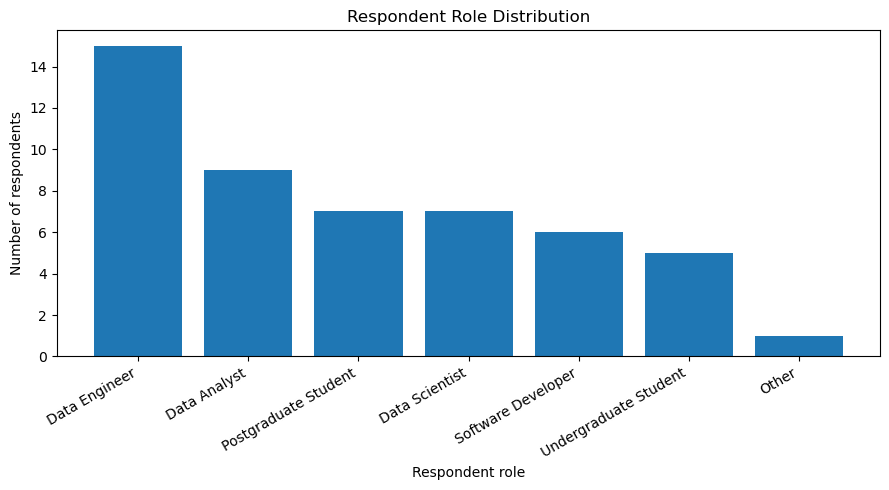

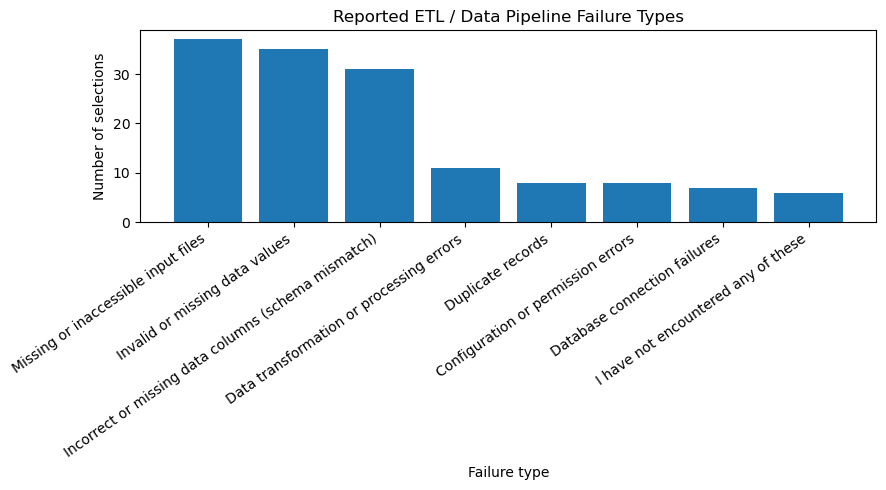

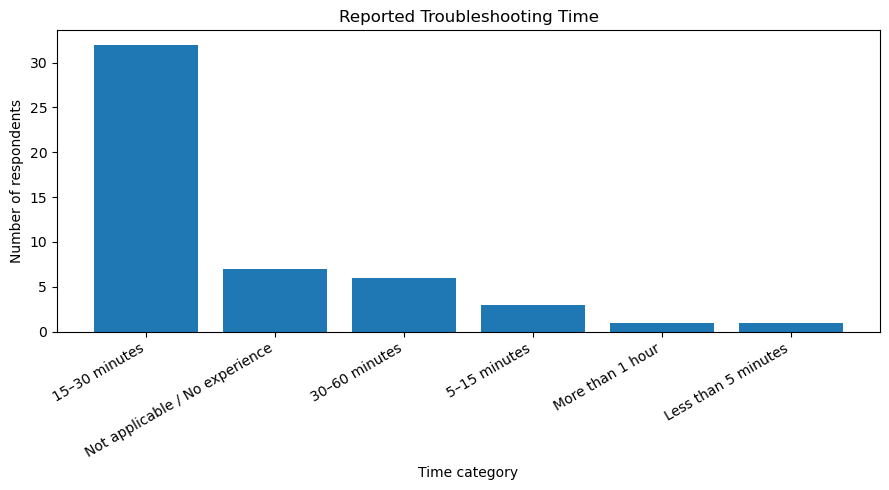

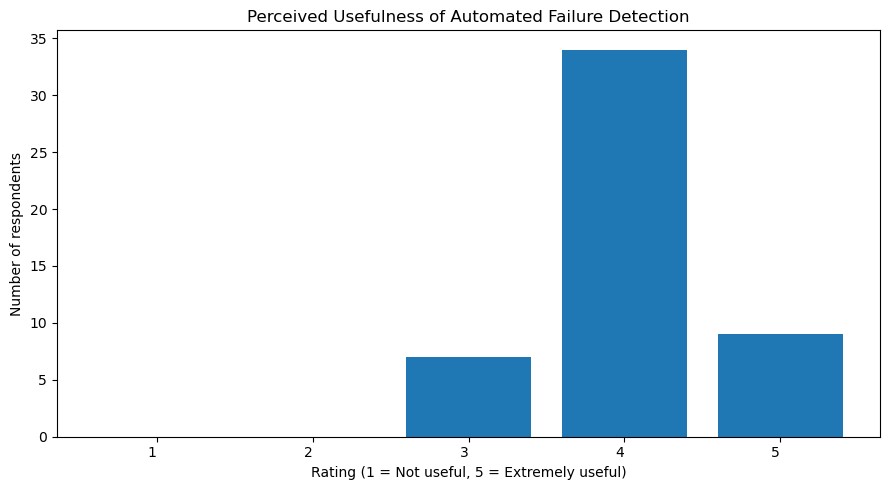

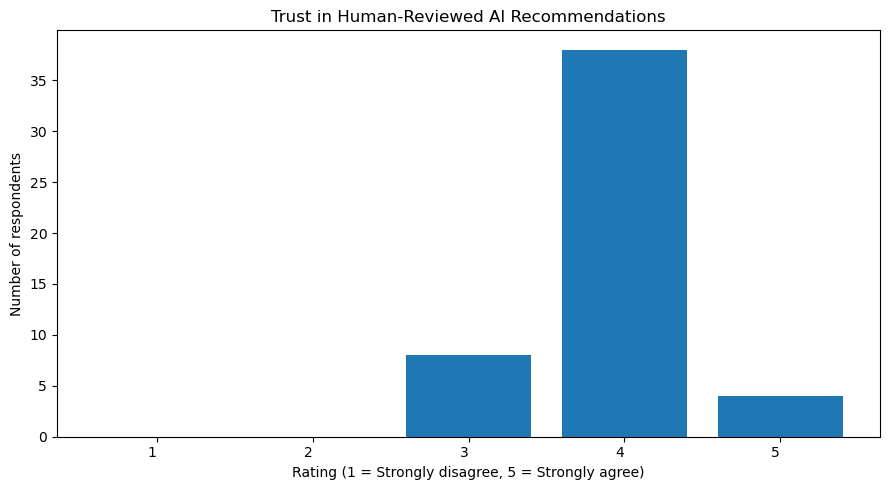

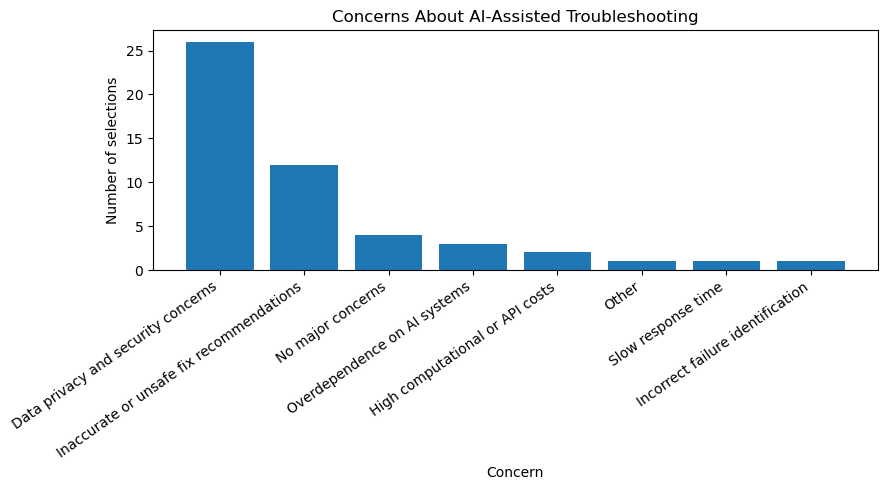

In [9]:
charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)

def make_bar_chart(labels, values, title, xlabel, ylabel, filename,
                   rotation=30, figsize=(9, 5)):
    plt.figure(figsize=figsize)
    plt.bar([str(label) for label in labels], values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotation, ha="right")
    plt.tight_layout()
    output_path = charts_dir / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    return output_path

chart_paths = []

chart_paths.append(make_bar_chart(
    role_frequency["Response"], role_frequency["Frequency"],
    "Respondent Role Distribution", "Respondent role",
    "Number of respondents", "01_role_distribution.png"
))

chart_paths.append(make_bar_chart(
    failure_types["Option"], failure_types["Selections"],
    "Reported ETL / Data Pipeline Failure Types", "Failure type",
    "Number of selections", "02_failure_types.png", rotation=35
))

chart_paths.append(make_bar_chart(
    time_frequency["Response"], time_frequency["Frequency"],
    "Reported Troubleshooting Time", "Time category",
    "Number of respondents", "03_troubleshooting_time.png"
))

chart_paths.append(make_bar_chart(
    usefulness_distribution["Rating"].astype(str),
    usefulness_distribution["Frequency"],
    "Perceived Usefulness of Automated Failure Detection",
    "Rating (1 = Not useful, 5 = Extremely useful)",
    "Number of respondents", "04_automation_usefulness.png", rotation=0
))

chart_paths.append(make_bar_chart(
    trust_distribution["Rating"].astype(str),
    trust_distribution["Frequency"],
    "Trust in Human-Reviewed AI Recommendations",
    "Rating (1 = Strongly disagree, 5 = Strongly agree)",
    "Number of respondents", "05_ai_recommendation_trust.png", rotation=0
))

chart_paths.append(make_bar_chart(
    ai_concerns["Option"], ai_concerns["Selections"],
    "Concerns About AI-Assisted Troubleshooting", "Concern",
    "Number of selections", "06_ai_concerns.png", rotation=35
))

## 10. Export analysis tables to Excel

In [10]:
output_file = "practical_6_statistical_analysis.xlsx"

tables_to_export = {
    "Analysis Data": analysis,
    "Data Quality": quality_summary,
    "Descriptive Stats": statistics_table,
    "Role Frequency": role_frequency,
    "Failure Experience": experience_frequency,
    "Failure Frequency": failure_frequency,
    "Troubleshooting Method": method_frequency,
    "Troubleshooting Time": time_frequency,
    "Failure Types": failure_types,
    "AI Concerns": ai_concerns,
    "ETL Familiarity": familiarity_distribution,
    "Automation Usefulness": usefulness_distribution,
    "AI Trust": trust_distribution
}

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Raw Responses", index=False)
    for sheet_name, table in tables_to_export.items():
        table.to_excel(writer, sheet_name=sheet_name, index=False)

print("Excel workbook created:", output_file)

Excel workbook created: practical_6_statistical_analysis.xlsx


## 11. Add charts and format the Excel workbook

In [ ]:
from openpyxl import load_workbook
from openpyxl.drawing.image import Image as XLImage

workbook = load_workbook(output_file)
charts_sheet = workbook.create_sheet("Charts")

row_positions = [1, 28, 55, 82, 109, 136]
for image_path, row in zip(chart_paths, row_positions):
    image = XLImage(str(image_path))
    image.width = 650
    image.height = 365
    charts_sheet.add_image(image, f"A{row}")

# Format worksheet headers and columns for readability.
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

for worksheet in workbook.worksheets:
    if worksheet.title == "Charts":
        continue
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions
    for cell in worksheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="24476B")
        cell.alignment = Alignment(wrap_text=True, vertical="center")
    worksheet.row_dimensions[1].height = 30
    for column_cells in worksheet.columns:
        max_length = max(
            len(str(cell.value)) if cell.value is not None else 0
            for cell in column_cells
        )
        worksheet.column_dimensions[
            get_column_letter(column_cells[0].column)
        ].width = min(max(max_length + 2, 12), 48)

workbook.save(output_file)
print("Charts added to Excel workbook.")
print("Final workbook:", output_file)


Charts added to Excel workbook.
Final workbook: practical_6_statistical_analysis.xlsx
